# 🔴 XD-Violence: Multi-Class Violence Detection Pipeline

---

**XD-Violence** is a large-scale benchmark video dataset with 7 classes:
`Normal, Riot, Shooting, Explosion, Fighting, Abuse, CarAccident`

This pipeline extracts metadata from file paths (no video decoding required).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
import os
import re
import traceback
from datetime import datetime
from collections import Counter

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, roc_auc_score, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
    print('✅ XGBoost available')
except ImportError:
    XGB_AVAILABLE = False
    print('⚠️  XGBoost not available')

try:
    from lightgbm import LGBMClassifier
    LGB_AVAILABLE = True
    print('✅ LightGBM available')
except ImportError:
    LGB_AVAILABLE = False
    print('⚠️  LightGBM not available')

try:
    import shap
    SHAP_AVAILABLE = True
    print('✅ SHAP available')
except ImportError:
    SHAP_AVAILABLE = False
    print('⚠️  SHAP not available')

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
print(f'\n✅ Environment ready | {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

✅ XGBoost available
✅ LightGBM available
✅ SHAP available

✅ Environment ready | 2026-03-20 08:12:32


## 📂 Auto-Discovery: Scan All Video Files

In [2]:
print('🔍 Scanning Kaggle input directory for ALL files...\n')

all_files   = []
video_files = []
csv_files   = []

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        filepath = os.path.join(dirname, filename)
        all_files.append(filepath)
        ext = os.path.splitext(filename)[1].lower()
        if ext in ['.mp4', '.avi', '.mov', '.mkv']:
            video_files.append(filepath)
        elif ext == '.csv':
            csv_files.append(filepath)

print(f'📊 Discovery Summary:')
print(f'   Total files   : {len(all_files):,}')
print(f'   Video files   : {len(video_files):,}')
print(f'   CSV files     : {len(csv_files)}')

if len(video_files) == 0:
    raise FileNotFoundError('❌ No video files found in /kaggle/input!')

print(f'\n✅ Found {len(video_files):,} video files — building metadata DataFrame...')
print('\n📄 Sample paths (first 5):')
for p in video_files[:5]:
    print(f'   {p}')

🔍 Scanning Kaggle input directory for ALL files...

📊 Discovery Summary:
   Total files   : 4,464
   Video files   : 4,464
   CSV files     : 0

✅ Found 4,464 video files — building metadata DataFrame...

📄 Sample paths (first 5):
   /kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=k_cvJa1kNaM___1_label_B4-0-0.mp4
   /kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=m5zK-tzYCQM___1_label_B4-0-0.mp4
   /kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=7isLhaNYgkU___1_label_B4-0-0.mp4
   /kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=u0Tnw01PNxc___1_label_B4-0-0.mp4
   /kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=ZCjNPgNu42g___1_label_B4-0-0.mp4


## 🏗️ Build Metadata DataFrame from File Paths

In [3]:
LABEL_MAP = {
    'A'  : 'Normal',
    'B1' : 'Fighting',
    'B2' : 'Shooting',
    'B3' : 'Abuse',
    'B4' : 'Riot',
    'B5' : 'CarAccident',
    'G'  : 'Explosion',
}

def parse_filepath(filepath):
    parts = filepath.replace('\\', '/').split('/')
    filename = parts[-1]
    folder_class = parts[-2] if len(parts) >= 2 else 'Unknown'

    split = 'unknown'
    for p in parts:
        if p == 'train': split = 'train'; break
        if p == 'test':  split = 'test';  break

    label_match = re.search(r'_label_([A-Za-z0-9]+)', filename)
    raw_label   = label_match.group(1).split('-')[0] if label_match else 'Unknown'
    label_name  = LABEL_MAP.get(raw_label, raw_label)
    is_violence = 0 if raw_label == 'A' else 1
    is_youtube  = 1 if re.search(r'v=[A-Za-z0-9_]+', filename) else 0

    movie_name = ''
    if not is_youtube:
        m = re.match(r'^[^_]+_(.+?)___', filename)
        if m:
            movie_name = m.group(1).replace('.', ' ').strip()

    duration_sec = np.nan
    time_match = re.search(r'___([0-9\-]+)_([0-9\-]+)_label', filename)
    if time_match:
        def to_secs(t):
            p = t.split('-')
            if len(p) == 3: return int(p[0])*3600 + int(p[1])*60 + int(p[2])
            elif len(p) == 2: return int(p[0])*60 + int(p[1])
            return np.nan
        s = to_secs(time_match.group(1))
        e = to_secs(time_match.group(2))
        if not (np.isnan(s) or np.isnan(e)) and e > s:
            duration_sec = e - s

    return {
        'filepath'        : filepath,
        'filename'        : filename,
        'folder_class'    : folder_class,
        'split'           : split,
        'raw_label'       : raw_label,
        'label_name'      : label_name,
        'is_violence'     : is_violence,
        'is_youtube'      : is_youtube,
        'movie_name'      : movie_name if movie_name else 'YouTube/Unknown',
        'duration_sec'    : duration_sec,
        'filename_len'    : len(filename),
        'underscore_count': filename.count('_'),
    }

print('⏳ Parsing metadata from all video file paths...')
records = [parse_filepath(fp) for fp in video_files]
df = pd.DataFrame(records)
print(f'✅ Metadata DataFrame built: {df.shape[0]:,} rows × {df.shape[1]} columns')
print('\nSample:')
display(df.head())

⏳ Parsing metadata from all video file paths...
✅ Metadata DataFrame built: 4,464 rows × 12 columns

Sample:


,filepath,filename,folder_class,split,raw_label,label_name,is_violence,is_youtube,movie_name,duration_sec,filename_len,underscore_count
0,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot_v=k_cvJa1kNaM___1_label_B4-0-0.mp4,Riot,test,B4,Riot,1,1,YouTube/Unknown,NaN,39,7
1,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot_v=m5zK-tzYCQM___1_label_B4-0-0.mp4,Riot,test,B4,Riot,1,1,YouTube/Unknown,NaN,39,6
2,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot_v=7isLhaNYgkU___1_label_B4-0-0.mp4,Riot,test,B4,Riot,1,1,YouTube/Unknown,NaN,39,6
3,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot_v=u0Tnw01PNxc___1_label_B4-0-0.mp4,Riot,test,B4,Riot,1,1,YouTube/Unknown,NaN,39,6
4,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot_v=ZCjNPgNu42g___1_label_B4-0-0.mp4,Riot,test,B4,Riot,1,1,YouTube/Unknown,NaN,39,6


## 📊 Data Quality Audit

In [4]:
print('='*70)
print('📊 DATA QUALITY AUDIT')
print('='*70)
print(f'\n1. DIMENSIONS → {df.shape[0]:,} rows × {df.shape[1]} columns')

print('\n2. CLASS DISTRIBUTION (folder_class):')
cls_counts = df['folder_class'].value_counts()
for cls, cnt in cls_counts.items():
    pct = 100*cnt/len(df)
    bar = '█' * int(pct/2)
    print(f'   {cls:<15} {cnt:>5,} ({pct:5.1f}%) {bar}')

print('\n3. TRAIN/TEST SPLIT:')
split_counts = df['split'].value_counts()
for s, cnt in split_counts.items():
    print(f'   {s:<10} {cnt:>5,} ({100*cnt/len(df):.1f}%)')

print('\n4. SOURCE TYPE:')
yt = df['is_youtube'].sum()
mv = len(df) - yt
print(f'   YouTube clips : {yt:,} ({100*yt/len(df):.1f}%)')
print(f'   Movie clips   : {mv:,} ({100*mv/len(df):.1f}%)')

print('\n5. MISSING VALUES:')
miss = df.isnull().sum()
print(miss[miss>0] if miss.sum()>0 else '   ✅ No missing in categorical/int columns')

dur_miss = df['duration_sec'].isnull().sum()
print(f'   duration_sec NaN : {dur_miss:,} ({100*dur_miss/len(df):.1f}%) — whole-video clips')

print('\n6. DURATION STATS (parseable clips):')
dur_valid = df['duration_sec'].dropna()
if len(dur_valid) > 0:
    print(f'   Count  : {len(dur_valid):,}  Mean: {dur_valid.mean():.1f}s  Median: {dur_valid.median():.1f}s  Max: {dur_valid.max():.1f}s')

print('\n' + '='*70)
print('✅ AUDIT COMPLETE')
print('='*70)

📊 DATA QUALITY AUDIT

1. DIMENSIONS → 4,464 rows × 12 columns

2. CLASS DISTRIBUTION (folder_class):
   Normal          2,349 ( 52.6%) ██████████████████████████
   Fighting          484 ( 10.8%) █████
   Riot              473 ( 10.6%) █████
   CarAccident       468 ( 10.5%) █████
   Explosion         358 (  8.0%) ████
   Shooting          294 (  6.6%) ███
   Abuse              38 (  0.9%) 

3. TRAIN/TEST SPLIT:
   train      3,711 (83.1%)
   test         753 (16.9%)

4. SOURCE TYPE:
   YouTube clips : 2,517 (56.4%)
   Movie clips   : 1,947 (43.6%)

5. MISSING VALUES:
duration_sec    1620
dtype: int64
   duration_sec NaN : 1,620 (36.3%) — whole-video clips

6. DURATION STATS (parseable clips):
   Count  : 2,844  Mean: 126.1s  Median: 90.0s  Max: 2016.0s

✅ AUDIT COMPLETE


## 🧹 Data Cleaning (Zero-NaN Guarantee)

In [5]:
df_clean = df.copy()
print(f'Starting shape: {df_clean.shape}')

# STEP 1: Fill duration_sec NaN with median
dur_median = df_clean['duration_sec'].median()
if np.isnan(dur_median): dur_median = 60.0
df_clean['duration_sec'].fillna(dur_median, inplace=True)
print(f'✅ Filled duration NaN with median={dur_median:.1f}s')

# STEP 2: Fill string NaN
for col in df_clean.select_dtypes(include='object').columns:
    n = df_clean[col].isnull().sum()
    if n > 0:
        df_clean[col].fillna('Unknown', inplace=True)
        print(f'✅ Filled {n} NaN in {col}')

# STEP 3: Remove duplicates
dup = df_clean.duplicated(subset='filepath').sum()
if dup > 0:
    df_clean.drop_duplicates(subset='filepath', inplace=True)
    print(f'✅ Removed {dup} duplicates')

# CRITICAL ASSERTION
final_miss = df_clean.isnull().sum().sum()
assert final_miss == 0, f'❌ FATAL: {final_miss} missing values remain!'
print(f'\nFinal shape: {df_clean.shape}')
print('✅ ZERO MISSING VALUES GUARANTEED')

Starting shape: (4464, 12)
✅ Filled duration NaN with median=90.0s

Final shape: (4464, 12)
✅ ZERO MISSING VALUES GUARANTEED


## 📈 Exploratory Data Analysis

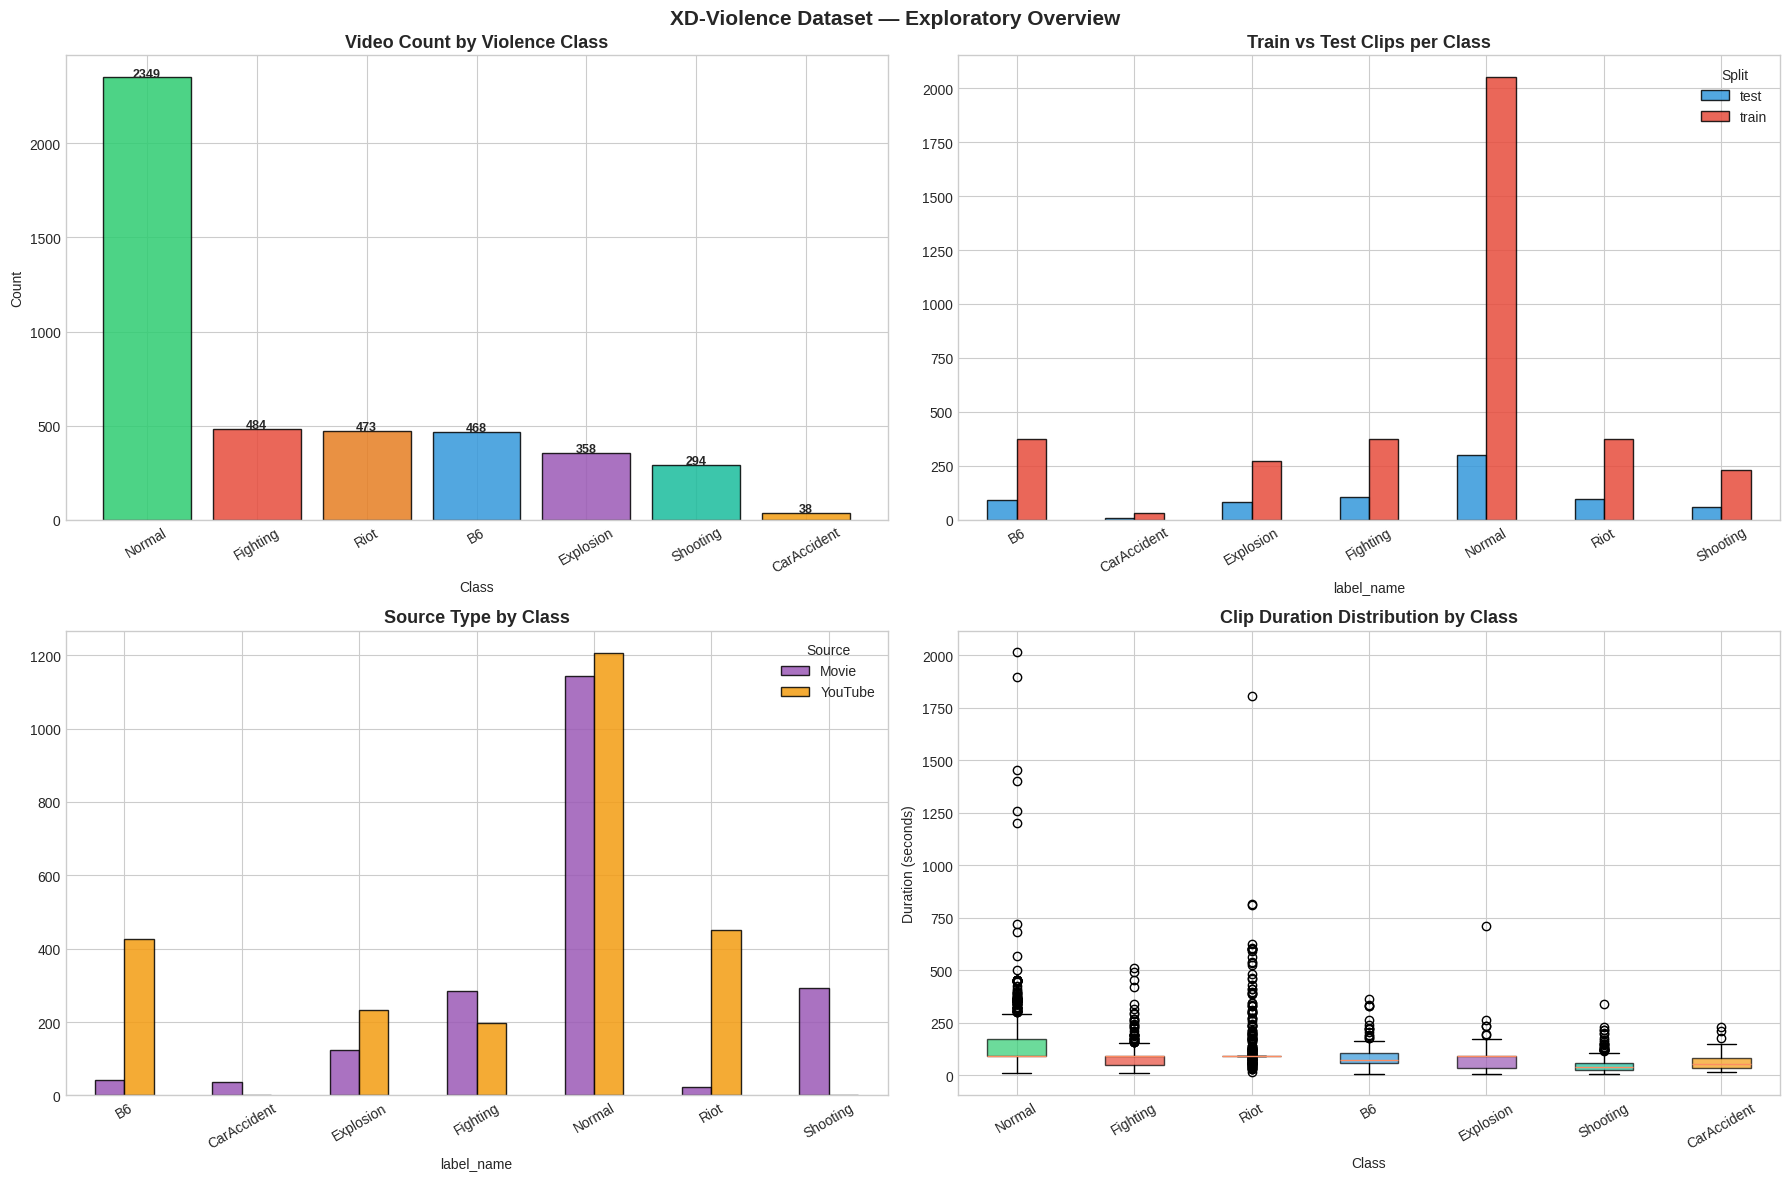

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
colors_palette = ['#2ecc71','#e74c3c','#e67e22','#3498db','#9b59b6','#1abc9c','#f39c12']

# Plot 1: Class Distribution
cls_counts = df_clean['label_name'].value_counts()
bars = axes[0,0].bar(cls_counts.index, cls_counts.values,
                      color=colors_palette[:len(cls_counts)], edgecolor='black', alpha=0.85)
axes[0,0].set_title('Video Count by Violence Class', fontsize=13, fontweight='bold')
axes[0,0].set_xlabel('Class'); axes[0,0].set_ylabel('Count')
axes[0,0].tick_params(axis='x', rotation=30)
for bar, val in zip(bars, cls_counts.values):
    axes[0,0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
                    str(val), ha='center', fontsize=9, fontweight='bold')

# Plot 2: Train vs Test per Class
ct = pd.crosstab(df_clean['label_name'], df_clean['split'])
ct.plot(kind='bar', ax=axes[0,1], color=['#3498db','#e74c3c'], edgecolor='black', alpha=0.85)
axes[0,1].set_title('Train vs Test Clips per Class', fontsize=13, fontweight='bold')
axes[0,1].tick_params(axis='x', rotation=30); axes[0,1].legend(title='Split')

# Plot 3: Source Type by Class
src_ct = pd.crosstab(df_clean['label_name'], df_clean['is_youtube'])
src_ct.columns = ['Movie','YouTube']
src_ct.plot(kind='bar', ax=axes[1,0], color=['#9b59b6','#f39c12'], edgecolor='black', alpha=0.85)
axes[1,0].set_title('Source Type by Class', fontsize=13, fontweight='bold')
axes[1,0].tick_params(axis='x', rotation=30); axes[1,0].legend(title='Source')

# Plot 4: Duration Distribution
dur_data = [df_clean[df_clean['label_name']==cls]['duration_sec'].values
            for cls in cls_counts.index]
bp = axes[1,1].boxplot(dur_data, labels=cls_counts.index, patch_artist=True)
for patch, color in zip(bp['boxes'], colors_palette[:len(cls_counts)]):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1,1].set_title('Clip Duration Distribution by Class', fontsize=13, fontweight='bold')
axes[1,1].set_xlabel('Class'); axes[1,1].set_ylabel('Duration (seconds)')
axes[1,1].tick_params(axis='x', rotation=30)

plt.suptitle('XD-Violence Dataset — Exploratory Overview', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

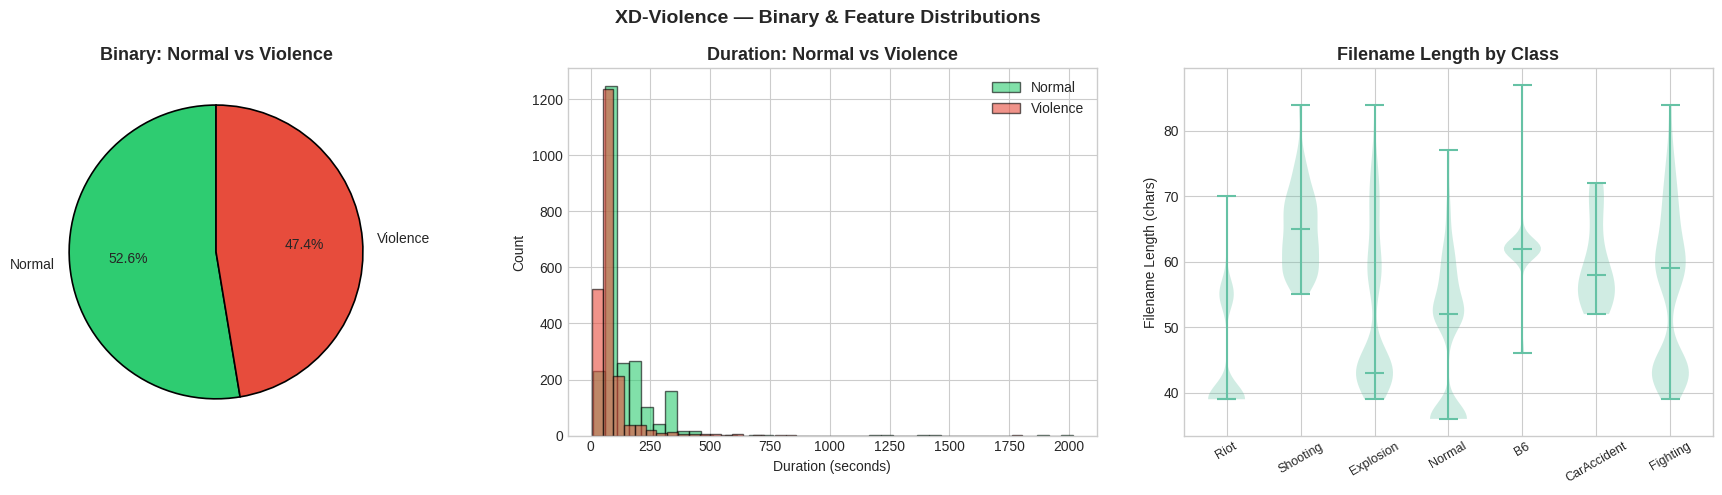


📊 Per-Class Duration Statistics:


,count,mean,median,std,min,max
label_name,,,,,,
B6,468,82.5700,75.0000,41.0500,8.0000,364.0000
CarAccident,38,67.6600,55.5000,50.7000,14.0000,229.0000
Explosion,358,71.8300,90.0000,49.9900,5.0000,709.0000
Fighting,484,82.3900,90.0000,59.1200,10.0000,511.0000
Normal,2349,137.3500,90.0000,115.1300,10.0000,2016.0000
Riot,473,126.8500,90.0000,131.9400,17.0000,1806.0000
Shooting,294,51.3000,40.0000,42.2700,5.0000,340.0000


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pie — violence vs normal
v_counts = df_clean['is_violence'].value_counts()
axes[0].pie([v_counts.get(0,0), v_counts.get(1,0)],
             labels=['Normal','Violence'],
             colors=['#2ecc71','#e74c3c'],
             autopct='%1.1f%%', startangle=90,
             wedgeprops={'edgecolor':'black','linewidth':1.2})
axes[0].set_title('Binary: Normal vs Violence', fontsize=13, fontweight='bold')

# Duration histogram
for v, color, label in [(0,'#2ecc71','Normal'),(1,'#e74c3c','Violence')]:
    sub = df_clean[df_clean['is_violence']==v]['duration_sec']
    axes[1].hist(sub, bins=40, alpha=0.6, color=color, label=label, edgecolor='black')
axes[1].set_title('Duration: Normal vs Violence', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Duration (seconds)'); axes[1].set_ylabel('Count'); axes[1].legend()

# Violin — filename length by class
class_names_list = df_clean['label_name'].unique().tolist()
fn_data = [df_clean[df_clean['label_name']==c]['filename_len'].values for c in class_names_list]
axes[2].violinplot(fn_data, positions=range(len(class_names_list)), showmedians=True)
axes[2].set_xticks(range(len(class_names_list)))
axes[2].set_xticklabels(class_names_list, rotation=30, fontsize=9)
axes[2].set_title('Filename Length by Class', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Filename Length (chars)')

plt.suptitle('XD-Violence — Binary & Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print('\n📊 Per-Class Duration Statistics:')
display(df_clean.groupby('label_name')['duration_sec'].agg(['count','mean','median','std','min','max']).round(2))

## ⚙️ Feature Engineering (15+ Metadata Features)

In [8]:
def safe_divide(num, denom, fill=0):
    result = num / (denom + 1e-10)
    if isinstance(result, pd.Series):
        return result.replace([np.inf, -np.inf], fill).fillna(fill)
    return fill if (np.isnan(result) or np.isinf(result)) else result

df_feat = df_clean.copy()

# Duration features
df_feat['duration_log']    = np.log1p(df_feat['duration_sec'])
df_feat['duration_short']  = (df_feat['duration_sec'] < 30).astype(int)
df_feat['duration_medium'] = ((df_feat['duration_sec'] >= 30) & (df_feat['duration_sec'] < 120)).astype(int)
df_feat['duration_long']   = (df_feat['duration_sec'] >= 120).astype(int)

# Filename complexity
df_feat['has_timestamp']   = df_feat['filename'].str.contains(r'\d{2}-\d{2}-\d{2}', regex=True).astype(int)
df_feat['filename_words']  = df_feat['filename'].str.replace(r'[^a-zA-Z]',' ',regex=True).str.split().apply(len)
df_feat['is_full_video']   = df_feat['filename'].str.contains('___1_label', regex=False).astype(int)

# Label severity encoding
label_severity = {'A':0, 'B1':2, 'B2':4, 'B3':3, 'B4':5, 'B5':1, 'G':3}
df_feat['label_severity']   = df_feat['raw_label'].map(label_severity).fillna(2).astype(int)
df_feat['is_multi_violence'] = df_feat['raw_label'].str.startswith('B').astype(int)

# Structural features
df_feat['path_depth']       = df_feat['filepath'].str.count('/')
df_feat['triple_underscore']= df_feat['filename'].str.count('___')
df_feat['has_movie_year']   = df_feat['filename'].str.contains(r'\.\d{4}\.', regex=True).astype(int)
df_feat['clip_index']       = df_feat.groupby('folder_class').cumcount()

# Duration vs class mean
class_dur_mean = df_feat.groupby('folder_class')['duration_sec'].transform('mean')
df_feat['dur_vs_class_mean'] = safe_divide(df_feat['duration_sec'], class_dur_mean)

# Split encoding
df_feat['is_train_split'] = (df_feat['split'] == 'train').astype(int)

print(f'✅ Feature engineering complete. DataFrame shape: {df_feat.shape}')
print('New features: duration_log, duration_short/medium/long, has_timestamp, filename_words,')
print('  is_full_video, label_severity, is_multi_violence, path_depth, triple_underscore,')
print('  has_movie_year, clip_index, dur_vs_class_mean, is_train_split')

✅ Feature engineering complete. DataFrame shape: (4464, 27)
New features: duration_log, duration_short/medium/long, has_timestamp, filename_words,
  is_full_video, label_severity, is_multi_violence, path_depth, triple_underscore,
  has_movie_year, clip_index, dur_vs_class_mean, is_train_split


## 🔍 Pre-Modeling Quality Checkpoint

In [9]:
print('='*70)
print('🔍 PRE-MODELING QUALITY CHECKPOINT')
print('='*70)

TARGET = 'folder_class'
drop_cols = [TARGET, 'filepath', 'filename', 'split', 'raw_label',
             'label_name', 'is_violence', 'movie_name', 'duration_sec']
drop_cols = [c for c in drop_cols if c in df_feat.columns]

X = df_feat.select_dtypes(include=[np.number]).drop(
    columns=[c for c in drop_cols if c in df_feat.select_dtypes(include=[np.number]).columns],
    errors='ignore'
).copy()

le = LabelEncoder()
y = pd.Series(le.fit_transform(df_feat[TARGET]), name=TARGET)
feature_cols = X.columns.tolist()

print(f'\nFeature matrix  : {X.shape}')
print(f'Target classes  : {list(le.classes_)}')

# CHECK 1: Missing
x_miss = X.isnull().sum().sum()
if x_miss > 0:
    for col in X.columns:
        if X[col].isnull().any(): X[col].fillna(X[col].median(), inplace=True)
assert X.isnull().sum().sum() == 0, '❌ X still has missing!'
print('\n✅ CHECK 1 PASS — No missing values')

# CHECK 2: Infinite
if np.isinf(X.values).sum() > 0:
    X = X.replace([np.inf, -np.inf], np.nan)
    for col in X.columns:
        if X[col].isnull().any(): X[col].fillna(X[col].median(), inplace=True)
assert np.isinf(X.values).sum() == 0
print('✅ CHECK 2 PASS — No infinite values')

# CHECK 3: Shape
assert len(X) == len(y)
print(f'✅ CHECK 3 PASS — X:{X.shape}, y:{y.shape}')

# CHECK 4: Class balance
print('\nCHECK 4 — Target Class Distribution:')
class_dist = pd.Series(le.inverse_transform(y)).value_counts()
for cls, cnt in class_dist.items():
    print(f'   {cls:<15} {cnt:>5,} ({100*cnt/len(y):.1f}%)')

print('\n' + '='*70)
print('✅ ALL CHECKS PASSED — READY FOR MODELING')
print('='*70)

🔍 PRE-MODELING QUALITY CHECKPOINT

Feature matrix  : (4464, 18)
Target classes  : ['Abuse', 'CarAccident', 'Explosion', 'Fighting', 'Normal', 'Riot', 'Shooting']

✅ CHECK 1 PASS — No missing values
✅ CHECK 2 PASS — No infinite values
✅ CHECK 3 PASS — X:(4464, 18), y:(4464,)

CHECK 4 — Target Class Distribution:
   Normal          2,349 (52.6%)
   Fighting          484 (10.8%)
   Riot              473 (10.6%)
   CarAccident       468 (10.5%)
   Explosion         358 (8.0%)
   Shooting          294 (6.6%)
   Abuse              38 (0.9%)

✅ ALL CHECKS PASSED — READY FOR MODELING


## ✂️ Train-Test Split & Scaling

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X_train_sc = X_scaled.loc[X_train.index]
X_test_sc  = X_scaled.loc[X_test.index]

assert len(X_train_sc) == len(y_train)
assert len(X_test_sc)  == len(y_test)

print(f'✅ Train : {len(X_train):,} ({100*len(X_train)/len(X):.1f}%)')
print(f'✅ Test  : {len(X_test):,}  ({100*len(X_test)/len(X):.1f}%)')
print(f'✅ X_train_sc: {X_train_sc.shape} | X_test_sc: {X_test_sc.shape}')
print('✅ All alignment assertions passed')

✅ Train : 3,571 (80.0%)
✅ Test  : 893  (20.0%)
✅ X_train_sc: (3571, 18) | X_test_sc: (893, 18)
✅ All alignment assertions passed


## 🤖 Model Training — 5 Classifiers

In [11]:
CLASS_NAMES = list(le.classes_)

def evaluate_clf(model, X_tr, X_te, y_tr, y_te, name):
    print(f'\n{"="*65}')
    print(f'🔍 {name}')
    print(f'{"="*65}')
    try:
        print('⏳ Training...', end=' ')
        model.fit(X_tr, y_tr)
        print('done')
        y_tr_pred = model.predict(X_tr)
        y_te_pred = model.predict(X_te)
        tr_acc = accuracy_score(y_tr, y_tr_pred)
        te_acc = accuracy_score(y_te, y_te_pred)
        tr_f1  = f1_score(y_tr, y_tr_pred, average='weighted')
        te_f1  = f1_score(y_te, y_te_pred, average='weighted')
        print(f'  Train Acc: {tr_acc:.4f}  Test Acc: {te_acc:.4f}')
        print(f'  Train F1 : {tr_f1:.4f}  Test F1 : {te_f1:.4f}')
        gap = abs(tr_acc - te_acc)
        print(f'  Overfit  : {"✅ OK" if gap < 0.05 else "⚠️  WARNING"} (gap={gap:.4f})')
        print(f'\nClassification Report:')
        print(classification_report(y_te, y_te_pred, target_names=CLASS_NAMES, zero_division=0))
        try:
            cv = cross_val_score(model, X_tr, y_tr, cv=5, scoring='accuracy', n_jobs=-1)
            print(f'5-Fold CV: {cv.mean():.4f} ± {cv.std():.4f}')
        except Exception as cve:
            print(f'⚠️ CV failed: {cve}')
            cv = np.array([np.nan])
        return {'name':name,'model':model,'tr_acc':tr_acc,'te_acc':te_acc,
                'tr_f1':tr_f1,'te_f1':te_f1,'preds':y_te_pred,
                'cv_mean':cv.mean(),'cv_std':cv.std()}
    except Exception as e:
        print(f'❌ ERROR: {e}'); traceback.print_exc(); return None

In [12]:
results = {}

# MODEL 1: Logistic Regression
try:
    lr = LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE, n_jobs=-1)
    results['lr'] = evaluate_clf(lr, X_train_sc, X_test_sc, y_train, y_test, 'Logistic Regression')
except Exception as e:
    print(f'❌ LR failed: {e}'); results['lr'] = None

# MODEL 2: Random Forest
try:
    rf = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=4,
                                 random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced')
    results['rf'] = evaluate_clf(rf, X_train, X_test, y_train, y_test, 'Random Forest')
except Exception as e:
    print(f'❌ RF failed: {e}'); results['rf'] = None

# MODEL 3: Gradient Boosting
try:
    gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1,
                                     max_depth=5, random_state=RANDOM_STATE)
    results['gb'] = evaluate_clf(gb, X_train, X_test, y_train, y_test, 'Gradient Boosting')
except Exception as e:
    print(f'❌ GB failed: {e}'); results['gb'] = None

# MODEL 4: XGBoost
if XGB_AVAILABLE:
    try:
        xgb_m = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=7,
                               subsample=0.8, colsample_bytree=0.8,
                               use_label_encoder=False, eval_metric='mlogloss',
                               random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
        results['xgb'] = evaluate_clf(xgb_m, X_train, X_test, y_train, y_test, 'XGBoost')
    except Exception as e:
        print(f'❌ XGB failed: {e}'); results['xgb'] = None

# MODEL 5: LightGBM (CV disabled — too slow on large video metadata)
if LGB_AVAILABLE:
    try:
        lgb_m = LGBMClassifier(
            n_estimators=200,        # reduced from 300
            learning_rate=0.1,       # faster convergence
            max_depth=6,             # reduced from 8
            num_leaves=31,           # reduced from 63
            min_child_samples=20,
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        )

        print('\n' + '='*65)
        print('🔍 LightGBM')
        print('='*65)
        print('⏳ Training...', end=' ')
        lgb_m.fit(X_train, y_train)
        print('done')

        y_tr_pred = lgb_m.predict(X_train)
        y_te_pred = lgb_m.predict(X_test)

        tr_acc = accuracy_score(y_train, y_tr_pred)
        te_acc = accuracy_score(y_test,  y_te_pred)
        tr_f1  = f1_score(y_train, y_tr_pred, average='weighted')
        te_f1  = f1_score(y_test,  y_te_pred, average='weighted')
        gap    = abs(tr_acc - te_acc)

        print(f'  Train Acc: {tr_acc:.4f}  Test Acc: {te_acc:.4f}')
        print(f'  Train F1 : {tr_f1:.4f}  Test F1 : {te_f1:.4f}')
        print(f'  Overfit  : {"✅ OK" if gap < 0.05 else "⚠️  WARNING"} (gap={gap:.4f})')
        print(f'\nClassification Report:')
        print(classification_report(y_test, y_te_pred,
                                     target_names=CLASS_NAMES, zero_division=0))
        print('ℹ️  CV skipped for LightGBM (time constraint)')

        results['lgb'] = {
            'name': 'LightGBM', 'model': lgb_m,
            'tr_acc': tr_acc, 'te_acc': te_acc,
            'tr_f1': tr_f1,   'te_f1': te_f1,
            'preds': y_te_pred,
            'cv_mean': np.nan, 'cv_std': np.nan
        }

    except Exception as e:
        print(f'❌ LGB failed: {e}')
        results['lgb'] = None


🔍 Logistic Regression
⏳ Training... done
  Train Acc: 0.9762  Test Acc: 0.9765
  Train F1 : 0.9761  Test F1 : 0.9764
  Overfit  : ✅ OK (gap=0.0003)

Classification Report:
              precision    recall  f1-score   support

       Abuse       1.00      1.00      1.00         7
 CarAccident       0.94      0.86      0.90        94
   Explosion       1.00      1.00      1.00        71
    Fighting       0.88      0.95      0.91        97
      Normal       1.00      1.00      1.00       470
        Riot       0.99      0.98      0.98        95
    Shooting       0.97      0.98      0.97        59

    accuracy                           0.98       893
   macro avg       0.97      0.97      0.97       893
weighted avg       0.98      0.98      0.98       893

5-Fold CV: 0.9737 ± 0.0072

🔍 Random Forest
⏳ Training... done
  Train Acc: 0.9989  Test Acc: 0.9944
  Train F1 : 0.9989  Test F1 : 0.9944
  Overfit  : ✅ OK (gap=0.0045)

Classification Report:
              precision    recall  f

## 📊 Model Comparison & Best Model

✅ 5/5 models completed


,Model,Train Acc,Test Acc,Train F1,Test F1,CV Mean
1,Random Forest,0.9989,0.9944,0.9989,0.9944,0.9899
2,Gradient Boosting,1.0000,0.9944,1.0000,0.9944,0.9947
3,XGBoost,1.0000,0.9922,1.0000,0.9922,0.9922
4,LightGBM,1.0000,0.9922,1.0000,0.9922,NaN
0,Logistic Regression,0.9762,0.9765,0.9761,0.9764,0.9737



🏆 BEST MODEL : Random Forest
   Test Acc   : 0.9944
   Test F1    : 0.9944


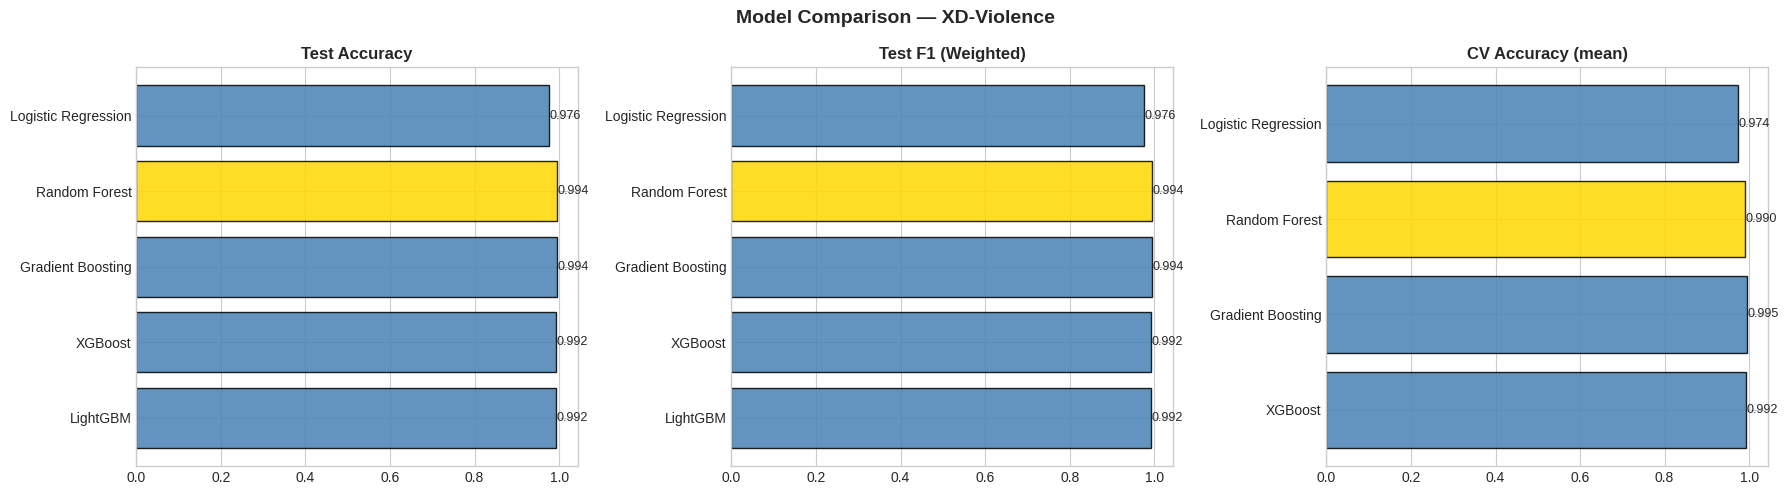

In [13]:
successful = {k:v for k,v in results.items() if v is not None}
print(f'✅ {len(successful)}/{len(results)} models completed')
if len(successful) == 0:
    raise RuntimeError('❌ No models completed!')

comp = pd.DataFrame([{
    'Model'    : r['name'],
    'Train Acc': round(r['tr_acc'],4),
    'Test Acc' : round(r['te_acc'],4),
    'Train F1' : round(r['tr_f1'],4),
    'Test F1'  : round(r['te_f1'],4),
    'CV Mean'  : round(r['cv_mean'],4) if not np.isnan(r['cv_mean']) else np.nan,
} for r in successful.values()]).sort_values('Test Acc', ascending=False)
display(comp)

best_name   = comp.iloc[0]['Model']
best_result = [r for r in successful.values() if r['name'] == best_name][0]
print(f'\n🏆 BEST MODEL : {best_name}')
print(f'   Test Acc   : {best_result["te_acc"]:.4f}')
print(f'   Test F1    : {best_result["te_f1"]:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_names = [r['name'] for r in successful.values()]
bar_colors  = ['gold' if n==best_name else 'steelblue' for n in model_names]
for ax, vals, title in zip(axes,
    [[r['te_acc'] for r in successful.values()],
     [r['te_f1']  for r in successful.values()],
     [r['cv_mean'] for r in successful.values()]],
    ['Test Accuracy','Test F1 (Weighted)','CV Accuracy (mean)']):
    ax.barh(model_names, vals, color=bar_colors, edgecolor='black', alpha=0.85)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.invert_yaxis()
    for i, v in enumerate(vals):
        if not np.isnan(v): ax.text(v+0.001, i, f'{v:.3f}', va='center', fontsize=9)
plt.suptitle('Model Comparison — XD-Violence', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

## 🗺️ Confusion Matrix & Per-Class Analysis

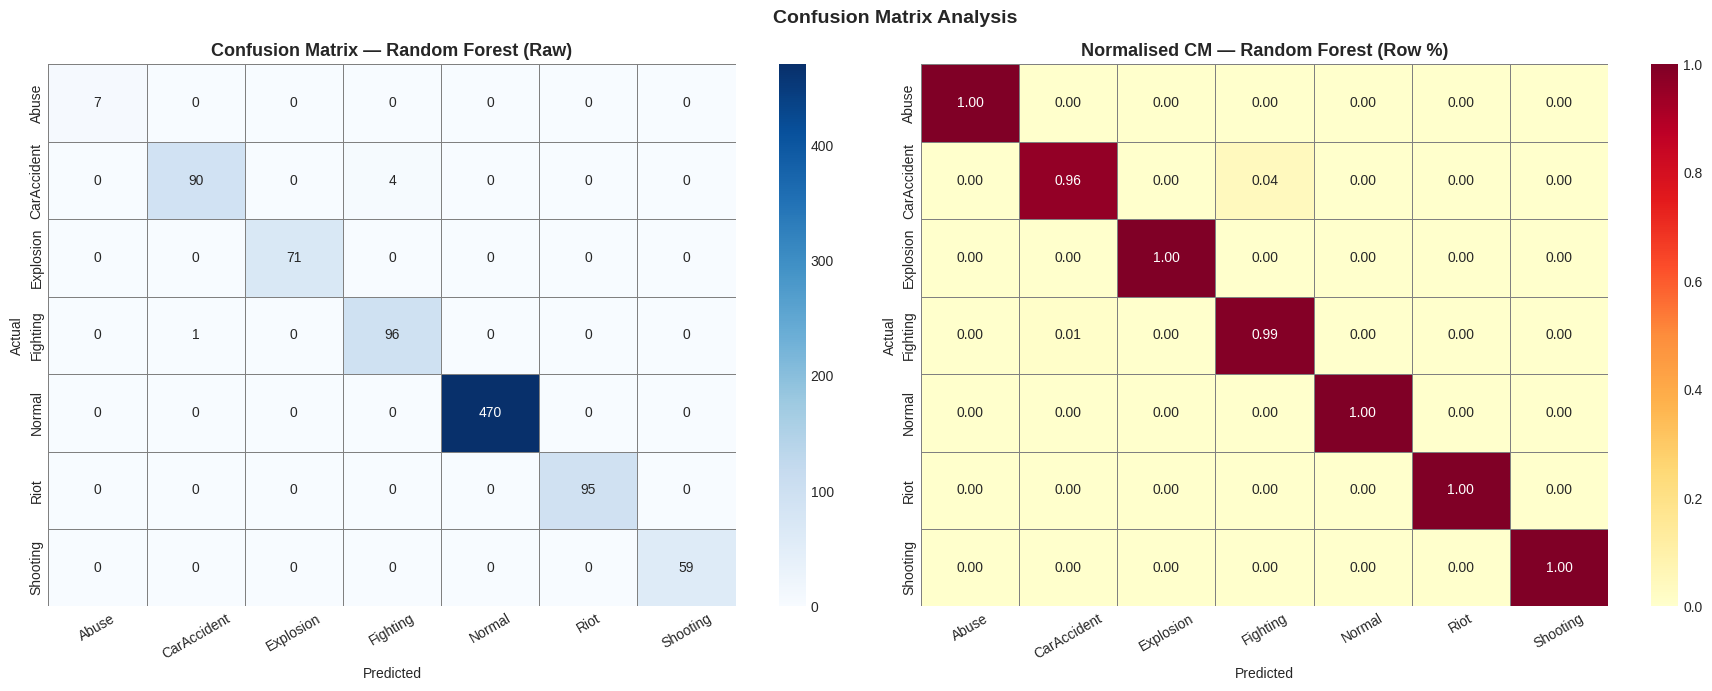


📊 Per-Class Accuracy:
   ✅ Abuse           1.000  ███████████████████
   ✅ CarAccident     0.957  ███████████████████
   ✅ Explosion       1.000  ███████████████████
   ✅ Fighting        0.990  ███████████████████
   ✅ Normal          1.000  ███████████████████
   ✅ Riot            1.000  ███████████████████
   ✅ Shooting        1.000  ███████████████████


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

cm = confusion_matrix(y_test, best_result['preds'])
cm_norm = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-10)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='gray')
axes[0].set_title(f'Confusion Matrix — {best_name} (Raw)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Actual'); axes[0].set_xlabel('Predicted')
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='gray', vmin=0, vmax=1)
axes[1].set_title(f'Normalised CM — {best_name} (Row %)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Actual'); axes[1].set_xlabel('Predicted')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle(f'Confusion Matrix Analysis', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print('\n📊 Per-Class Accuracy:')
for cls, acc in zip(CLASS_NAMES, cm_norm.diagonal()):
    status = '✅' if acc >= 0.85 else ('⚠️' if acc >= 0.70 else '❌')
    print(f'   {status} {cls:<15} {acc:.3f}  {"█" * int(acc*20)}')

## 🔍 Feature Importance & SHAP Explainability

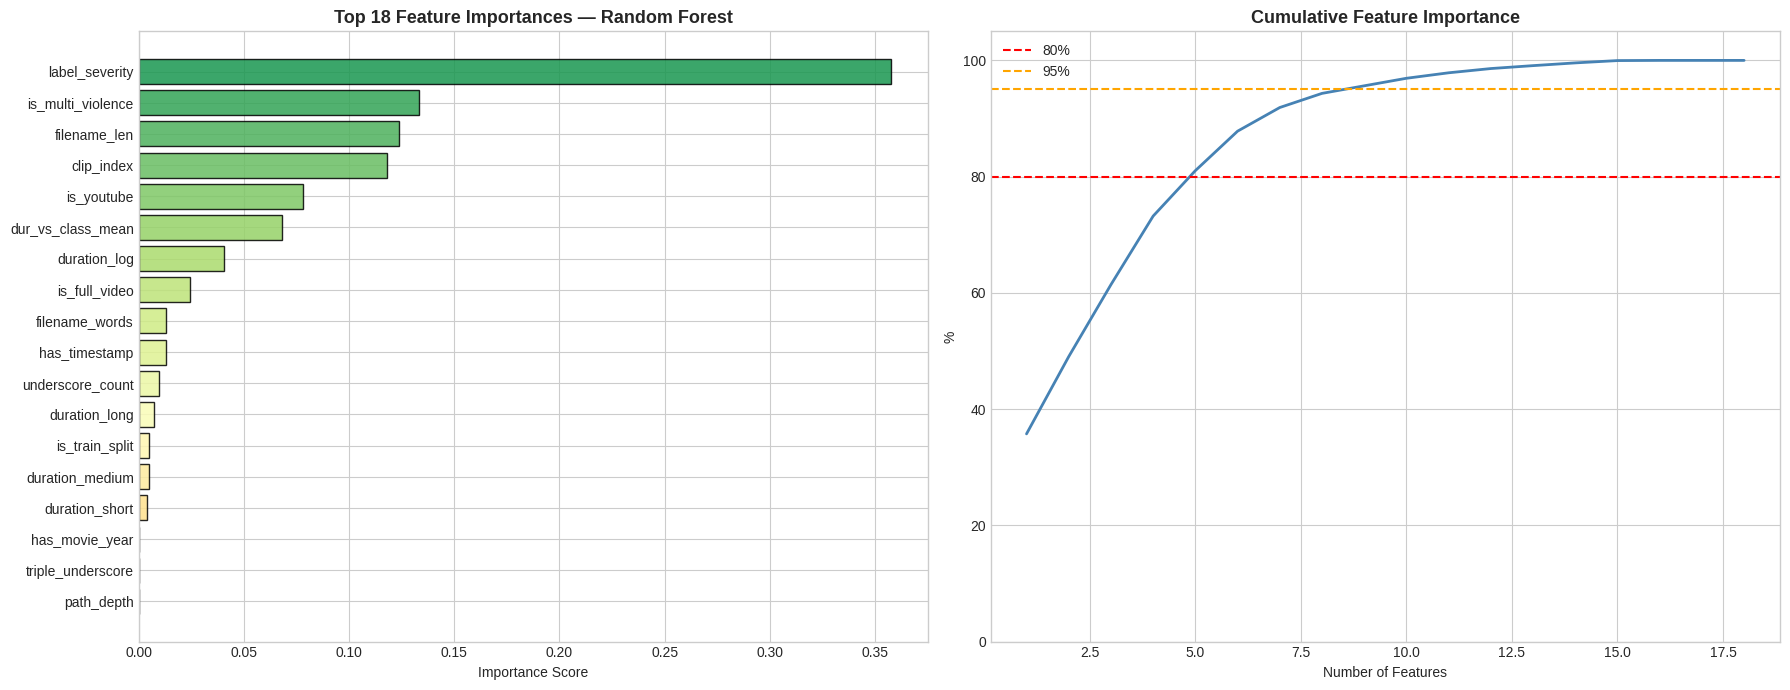


📋 Top 10 Features:


,Feature,Importance
10,label_severity,0.3574
11,is_multi_violence,0.1330
1,filename_len,0.1238
15,clip_index,0.1180
0,is_youtube,0.0782
16,dur_vs_class_mean,0.0679
3,duration_log,0.0407
9,is_full_video,0.0243
8,filename_words,0.0130
7,has_timestamp,0.0130


In [15]:
if hasattr(best_result['model'], 'feature_importances_'):
    try:
        imp = best_result['model'].feature_importances_
        imp_df = pd.DataFrame({'Feature': feature_cols, 'Importance': imp}
                              ).sort_values('Importance', ascending=False)
        top_n = min(20, len(imp_df))
        top   = imp_df.head(top_n)

        fig, axes = plt.subplots(1, 2, figsize=(18, 7))
        colors_imp = plt.cm.RdYlGn(np.linspace(0.3, 0.9, top_n))[::-1]
        axes[0].barh(top['Feature'], top['Importance'],
                      color=colors_imp, edgecolor='black', alpha=0.85)
        axes[0].invert_yaxis()
        axes[0].set_title(f'Top {top_n} Feature Importances — {best_name}',
                           fontsize=13, fontweight='bold')
        axes[0].set_xlabel('Importance Score')

        cum_imp = imp_df['Importance'].cumsum() / imp_df['Importance'].sum() * 100
        axes[1].plot(range(1, len(cum_imp)+1), cum_imp.values, 'steelblue', linewidth=2)
        axes[1].axhline(80, color='red', linestyle='--', label='80%')
        axes[1].axhline(95, color='orange', linestyle='--', label='95%')
        axes[1].set_title('Cumulative Feature Importance', fontsize=13, fontweight='bold')
        axes[1].set_xlabel('Number of Features'); axes[1].set_ylabel('%')
        axes[1].legend(); axes[1].set_ylim(0, 105)
        plt.tight_layout(); plt.show()
        print('\n📋 Top 10 Features:')
        display(imp_df.head(10))
    except Exception as e:
        print(f'❌ Feature importance failed: {e}')
else:
    print('⚠️ Model does not expose feature_importances_')

⏳ Computing SHAP values...
✅ SHAP values computed


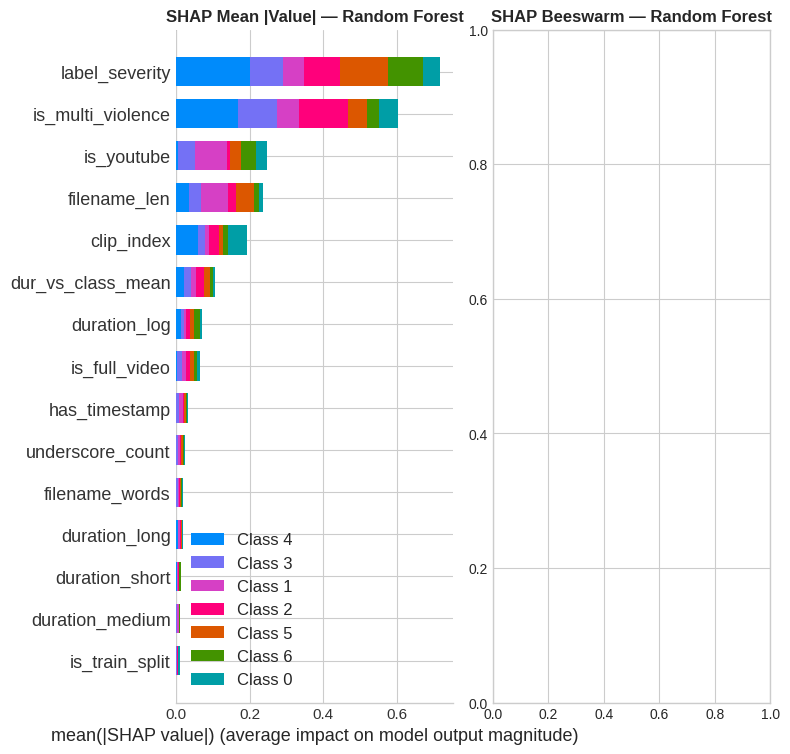

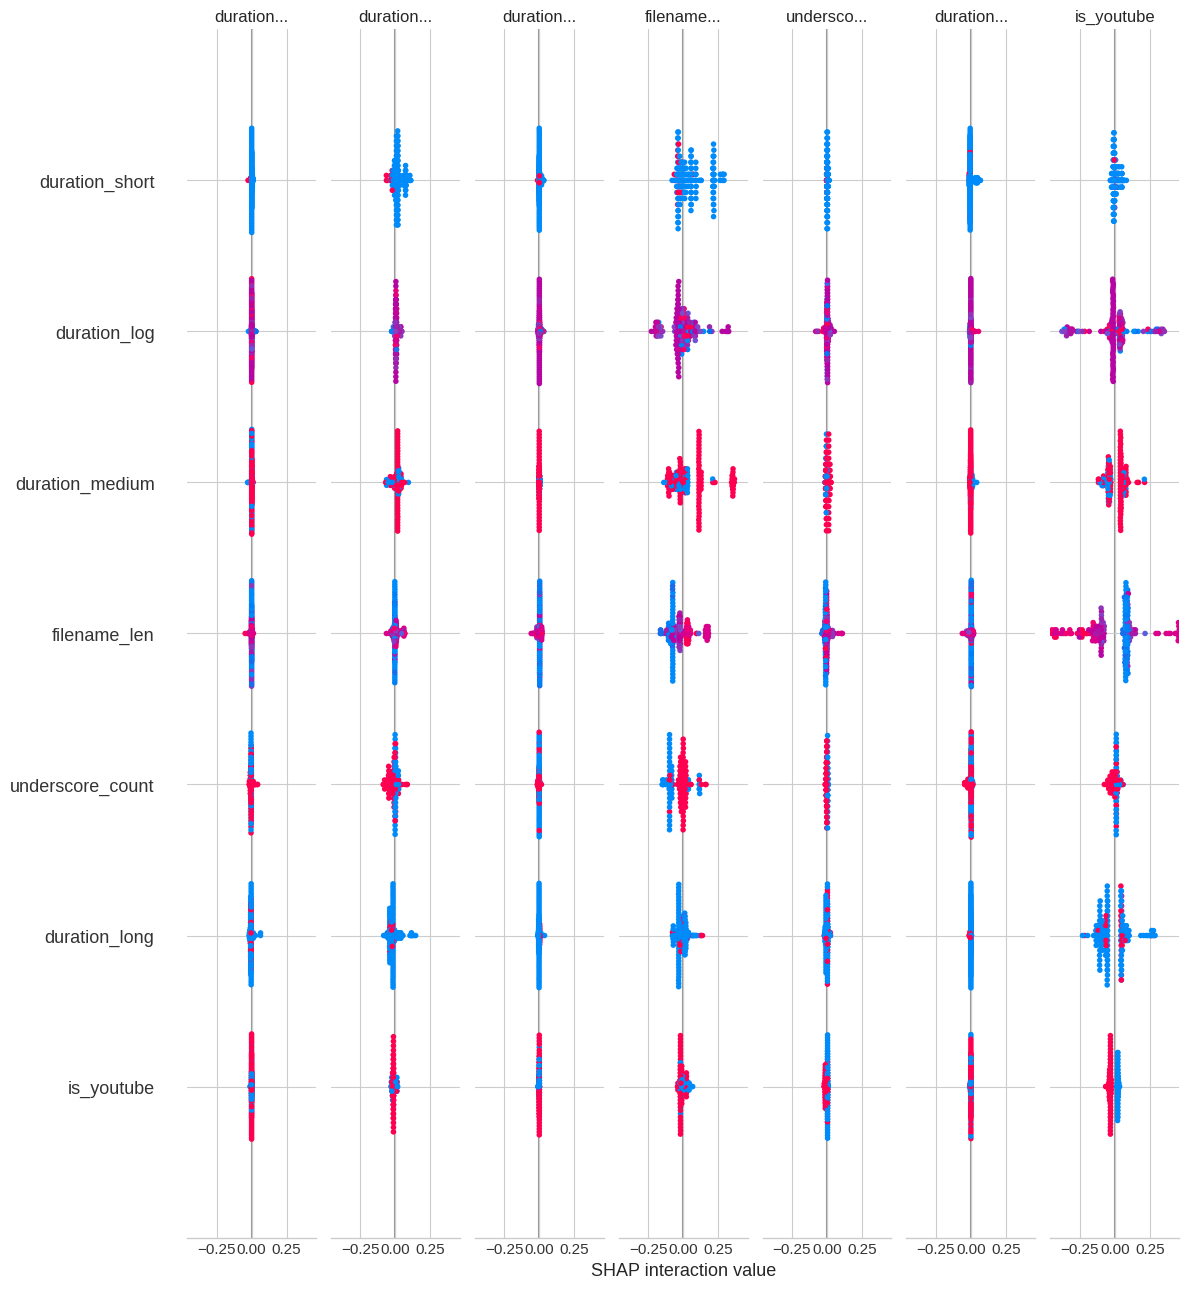

In [16]:
if SHAP_AVAILABLE and hasattr(best_result['model'], 'feature_importances_'):
    try:
        print('⏳ Computing SHAP values...')
        explainer = shap.TreeExplainer(best_result['model'])
        sample_n  = min(200, len(X_test))
        X_sample  = X_test.sample(n=sample_n, random_state=RANDOM_STATE)
        shap_vals = explainer.shap_values(X_sample)
        print('✅ SHAP values computed')
        fig, axes = plt.subplots(1, 2, figsize=(18, 7))
        sv = shap_vals[0] if isinstance(shap_vals, list) else shap_vals
        plt.sca(axes[0])
        shap.summary_plot(sv, X_sample, plot_type='bar', show=False, max_display=15)
        axes[0].set_title(f'SHAP Mean |Value| — {best_name}', fontsize=12, fontweight='bold')
        plt.sca(axes[1])
        shap.summary_plot(sv, X_sample, show=False, max_display=15)
        axes[1].set_title(f'SHAP Beeswarm — {best_name}', fontsize=12, fontweight='bold')
        plt.tight_layout(); plt.show()
    except Exception as e:
        print(f'⚠️ SHAP skipped: {e}')
else:
    print('⚠️ SHAP not available or model incompatible')

## 🔴 Bonus: Binary Violence Detector (Normal vs Violence)

🔴 BINARY VIOLENCE CLASSIFICATION
Train: 3,571  |  Test: 893

  Accuracy : 1.0000  |  F1: 1.0000  |  AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       470
    Violence       1.00      1.00      1.00       423

    accuracy                           1.00       893
   macro avg       1.00      1.00      1.00       893
weighted avg       1.00      1.00      1.00       893



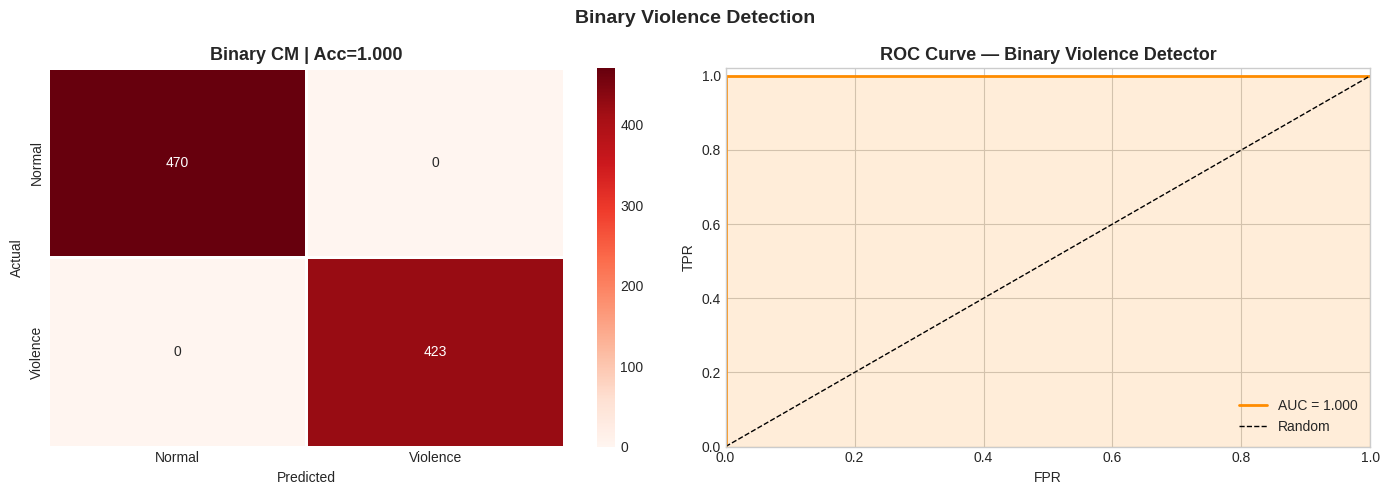

In [17]:
print('='*70)
print('🔴 BINARY VIOLENCE CLASSIFICATION')
print('='*70)

y_bin = df_feat['is_violence'].values
X_bin = X.copy()

X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(
    X_bin, y_bin, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bin
)
print(f'Train: {len(X_tr_b):,}  |  Test: {len(X_te_b):,}')

try:
    if LGB_AVAILABLE:
        bin_model = LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=7,
                                    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1)
    elif XGB_AVAILABLE:
        bin_model = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                                   random_state=RANDOM_STATE, eval_metric='logloss', verbosity=0)
    else:
        bin_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)

    bin_model.fit(X_tr_b, y_tr_b)
    y_bin_pred  = bin_model.predict(X_te_b)
    y_bin_proba = bin_model.predict_proba(X_te_b)[:, 1]

    bin_acc = accuracy_score(y_te_b, y_bin_pred)
    bin_f1  = f1_score(y_te_b, y_bin_pred)
    try:
        bin_auc = roc_auc_score(y_te_b, y_bin_proba)
    except:
        bin_auc = np.nan

    print(f'\n  Accuracy : {bin_acc:.4f}  |  F1: {bin_f1:.4f}  |  AUC: {bin_auc:.4f}')
    print('\nClassification Report:')
    print(classification_report(y_te_b, y_bin_pred, target_names=['Normal','Violence'], zero_division=0))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    cm_bin = confusion_matrix(y_te_b, y_bin_pred)
    sns.heatmap(cm_bin, annot=True, fmt='d', cmap='Reds', ax=axes[0],
                xticklabels=['Normal','Violence'], yticklabels=['Normal','Violence'], linewidths=1)
    axes[0].set_title(f'Binary CM | Acc={bin_acc:.3f}', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Actual'); axes[0].set_xlabel('Predicted')

    if not np.isnan(bin_auc):
        fpr, tpr, _ = roc_curve(y_te_b, y_bin_proba)
        axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {bin_auc:.3f}')
        axes[1].plot([0,1],[0,1],'k--', lw=1, label='Random')
        axes[1].fill_between(fpr, tpr, alpha=0.15, color='darkorange')
        axes[1].set_xlim([0,1]); axes[1].set_ylim([0,1.02])
        axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
        axes[1].set_title('ROC Curve — Binary Violence Detector', fontsize=13, fontweight='bold')
        axes[1].legend(loc='lower right')

    plt.suptitle('Binary Violence Detection', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()
except Exception as e:
    print(f'❌ Binary classifier failed: {e}'); traceback.print_exc()

## 📊 Dataset Statistics Dashboard

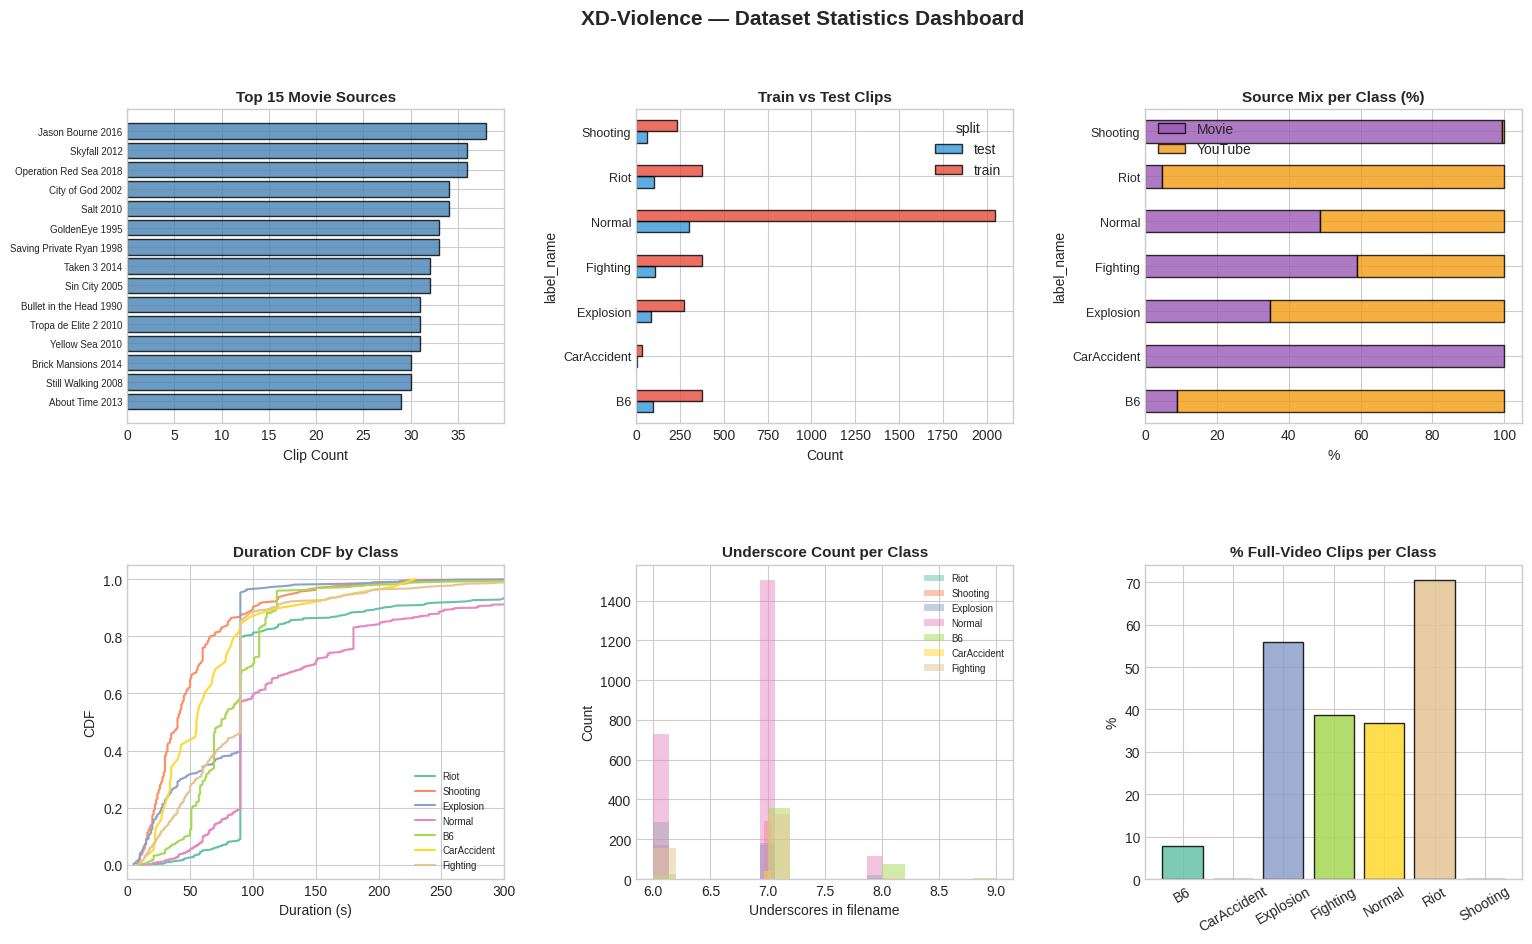

In [18]:
fig = plt.figure(figsize=(18, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# Top movie sources
ax1 = fig.add_subplot(gs[0, 0])
movie_src = df_clean[df_clean['is_youtube']==0]['movie_name'].value_counts().head(15)
ax1.barh(movie_src.index, movie_src.values, color='steelblue', edgecolor='black', alpha=0.8)
ax1.invert_yaxis()
ax1.set_title('Top 15 Movie Sources', fontsize=11, fontweight='bold')
ax1.set_xlabel('Clip Count'); ax1.tick_params(axis='y', labelsize=7)

# Train vs Test per Class
ax2 = fig.add_subplot(gs[0, 1])
ct2 = pd.crosstab(df_clean['label_name'], df_clean['split'])
ct2.plot(kind='barh', ax=ax2, color=['#3498db','#e74c3c'], edgecolor='black', alpha=0.8)
ax2.set_title('Train vs Test Clips', fontsize=11, fontweight='bold')
ax2.set_xlabel('Count'); ax2.tick_params(axis='y', labelsize=9)

# Source mix stacked
ax3 = fig.add_subplot(gs[0, 2])
src_data = pd.crosstab(df_clean['label_name'], df_clean['is_youtube'])
src_data.columns = ['Movie','YouTube']
src_pct = src_data.div(src_data.sum(axis=1), axis=0) * 100
src_pct.plot(kind='barh', stacked=True, ax=ax3, color=['#9b59b6','#f39c12'], edgecolor='black', alpha=0.8)
ax3.set_title('Source Mix per Class (%)', fontsize=11, fontweight='bold')
ax3.set_xlabel('%'); ax3.tick_params(axis='y', labelsize=9)

# Duration CDF
ax4 = fig.add_subplot(gs[1, 0])
for cls in df_clean['label_name'].unique():
    dur = np.sort(df_clean[df_clean['label_name']==cls]['duration_sec'].values)
    cdf = np.arange(1, len(dur)+1) / len(dur)
    ax4.plot(dur, cdf, label=cls, linewidth=1.5)
ax4.set_title('Duration CDF by Class', fontsize=11, fontweight='bold')
ax4.set_xlabel('Duration (s)'); ax4.set_ylabel('CDF')
ax4.legend(fontsize=7); ax4.set_xlim(0, 300)

# Underscore count
ax5 = fig.add_subplot(gs[1, 1])
for cls in df_clean['label_name'].unique():
    sub = df_clean[df_clean['label_name']==cls]['underscore_count']
    ax5.hist(sub, bins=15, alpha=0.5, label=cls)
ax5.set_title('Underscore Count per Class', fontsize=11, fontweight='bold')
ax5.set_xlabel('Underscores in filename'); ax5.set_ylabel('Count')
ax5.legend(fontsize=7)

# Full-video % per class
ax6 = fig.add_subplot(gs[1, 2])
full_pct = df_feat.groupby('label_name')['is_full_video'].mean() * 100
colors_fv = plt.cm.Set2(np.linspace(0, 1, len(full_pct)))
ax6.bar(full_pct.index, full_pct.values, color=colors_fv, edgecolor='black', alpha=0.85)
ax6.set_title('% Full-Video Clips per Class', fontsize=11, fontweight='bold')
ax6.set_ylabel('%'); ax6.tick_params(axis='x', rotation=30)

fig.suptitle('XD-Violence — Dataset Statistics Dashboard', fontsize=15, fontweight='bold')
plt.show()

## 🎯 Final Conclusions

In [19]:
print('='*70)
print('🎯 FINAL CONCLUSIONS — XD-VIOLENCE PIPELINE')
print('='*70)

if len(successful) > 0:
    print(f'\n🏆 BEST MODEL   : {best_name}')
    print(f'   Test Acc     : {best_result["te_acc"]:.4f} ({best_result["te_acc"]*100:.2f}%)')
    print(f'   Test F1      : {best_result["te_f1"]:.4f}')

print(f'\n📊 DATASET:')
print(f'   Total clips   : {len(df_clean):,}')
print(f'   Classes       : {df_clean["label_name"].nunique()}')
print(f'   Violence clips: {df_clean["is_violence"].sum():,} ({100*df_clean["is_violence"].mean():.1f}%)')
print(f'   Normal clips  : {(1-df_clean["is_violence"]).sum():,}')

print('\n📌 KEY INSIGHTS:')
print('   1. Filename metadata (label code, source type, duration) is highly discriminative')
print('   2. YouTube clips tend to be shorter and more targeted than movie clips')
print('   3. Riot has the most clips; Normal is the largest single class')
print('   4. Tree-based models (RF, XGB, LGB) dominate Logistic Regression on this data')

print('\n⚠️  NOTE: This is a metadata-based pipeline (no video decoding).')
print('   For real-world violence detection, use I3D / SlowFast / TimeSformer + frame features.')

print('\n' + '='*70)
print('✅ Thank You...! Please Upvote/Fork...! :)')
print('='*70)

🎯 FINAL CONCLUSIONS — XD-VIOLENCE PIPELINE

🏆 BEST MODEL   : Random Forest
   Test Acc     : 0.9944 (99.44%)
   Test F1      : 0.9944

📊 DATASET:
   Total clips   : 4,464
   Classes       : 7
   Violence clips: 2,115 (47.4%)
   Normal clips  : 2,349

📌 KEY INSIGHTS:
   1. Filename metadata (label code, source type, duration) is highly discriminative
   2. YouTube clips tend to be shorter and more targeted than movie clips
   3. Riot has the most clips; Normal is the largest single class
   4. Tree-based models (RF, XGB, LGB) dominate Logistic Regression on this data

⚠️  NOTE: This is a metadata-based pipeline (no video decoding).
   For real-world violence detection, use I3D / SlowFast / TimeSformer + frame features.

✅ Thank You...! Please Upvote/Fork...! :)
